# Level 3 · Task 2 — Support Vector Machine (SVM) for Classification
**Codveda Technology — Machine Learning Internship**

**Goal:** binary classification of customer **churn** with Support Vector Machines.

**Dataset:** telecom churn — `churn-bigml-80.csv` (train) / `churn-bigml-20.csv` (test), ~14.5 % churners.

**Objectives covered**
1. Train an SVM model on a labeled dataset
2. Use different kernels (linear, RBF — plus polynomial for reference) and compare performance
3. Visualize the decision boundary
4. Evaluate with accuracy, precision, recall and AUC

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from time import time
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load & preprocess
SVMs are **distance-based**, so scaling is essential — every numeric feature is standardized inside the pipeline.
Charge columns (exact multiples of minutes) are dropped; `State` is dropped too (51 sparse dummies showed no predictive value
in the Random Forest analysis and slow the SVM down); `Area code` is one-hot encoded.

In [2]:
train = pd.read_csv(DATA / "churn-bigml-80.csv")
test = pd.read_csv(DATA / "churn-bigml-20.csv")

def prepare(df):
    df = df.drop(columns=[c for c in df.columns if "charge" in c] + ["State"]).copy()
    df["International plan"] = (df["International plan"] == "Yes").astype(int)
    df["Voice mail plan"] = (df["Voice mail plan"] == "Yes").astype(int)
    df["Area code"] = df["Area code"].astype(str)
    df["Churn"] = df["Churn"].astype(int)
    return df

tr, te = prepare(train), prepare(test)
X_train, y_train = tr.drop(columns="Churn"), tr["Churn"]
X_test, y_test = te.drop(columns="Churn"), te["Churn"]
numeric = [c for c in X_train.columns if c not in ["Area code", "International plan", "Voice mail plan"]]
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", ["International plan", "Voice mail plan"]),
    ("cat", OneHotEncoder(drop="first"), ["Area code"]),
])
print("Train:", X_train.shape, "| Test:", X_test.shape, "| churn rate:", round(y_train.mean(), 3))

Train: (2666, 14) | Test: (667, 14) | churn rate: 0.146


## 2. Train SVMs with different kernels (tuned with 5-fold CV)
* **Linear** kernel — a straight hyperplane; only `C` (regularisation strength) is tuned.
* **RBF** (Gaussian) kernel — flexible, curved boundaries; `C` and `gamma` (how local each support vector's influence is) are tuned.
* **Polynomial** kernel (degree 2–3) — included as an extra comparison.

`class_weight="balanced"` makes errors on the minority (churn) class cost more. Models are selected on **ROC-AUC**.

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    "Linear": {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10]},
    "RBF": {"svc__kernel": ["rbf"], "svc__C": [0.3, 1, 3, 10, 30], "svc__gamma": ["scale", 0.01, 0.03, 0.1]},
    "Polynomial": {"svc__kernel": ["poly"], "svc__degree": [2, 3], "svc__C": [0.1, 1, 10], "svc__gamma": ["scale"]},
}
models, cv_rows = {}, []
for name, grid in grids.items():
    pipe = Pipeline([("prep", preprocess), ("svc", SVC(class_weight="balanced", random_state=RANDOM_STATE))])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    t0 = time(); gs.fit(X_train, y_train)
    models[name] = gs.best_estimator_
    cv_rows.append({"Kernel": name, "best params": {k.replace("svc__", ""): v for k, v in gs.best_params_.items() if k != "svc__kernel"},
                    "CV ROC-AUC": round(gs.best_score_, 3), "fit time (s)": round(time() - t0, 1),
                    "# support vectors": int(gs.best_estimator_.named_steps["svc"].n_support_.sum())})
pd.DataFrame(cv_rows).set_index("Kernel")

,best params,CV ROC-AUC,fit time (s),# support vectors
Kernel,,,,
Linear,{'C': 10},0.814,5.1,1574
RBF,"{'C': 1, 'gamma': 'scale'}",0.891,7.2,1328
Polynomial,"{'C': 1, 'degree': 2, 'gamma': 'scale'}",0.873,2.2,1290


## 3. Compare kernels on the test set

In [4]:
rows, scores = [], {}
for name, m in models.items():
    pred = m.predict(X_test)
    score = m.decision_function(X_test)          # signed distance to the hyperplane → used for ROC / AUC
    scores[name] = score
    rows.append({"Kernel": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "AUC": roc_auc_score(y_test, score)})
results = pd.DataFrame(rows).set_index("Kernel").round(3)
results

,Accuracy,Precision,Recall,F1,AUC
Kernel,,,,,
Linear,0.772,0.362,0.789,0.497,0.832
RBF,0.879,0.554,0.758,0.640,0.918
Polynomial,0.852,0.487,0.768,0.596,0.896


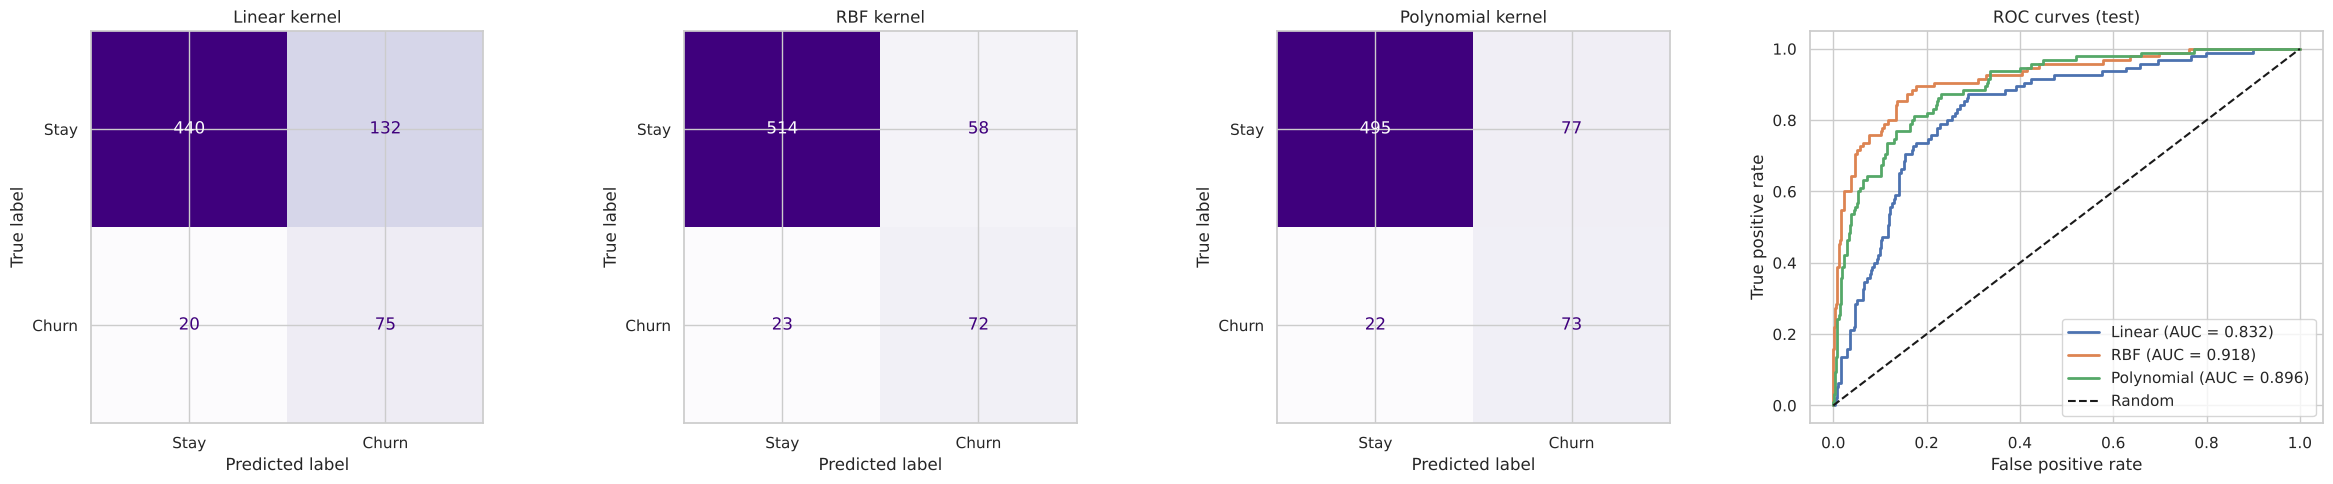

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, (name, m) in zip(axes[:3], models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=["Stay", "Churn"],
                                            cmap="Purples", colorbar=False, ax=ax)
    ax.set_title(f"{name} kernel")
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[3].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, s):.3f})")
axes[3].plot([0, 1], [0, 1], "k--", label="Random")
axes[3].set_xlabel("False positive rate"); axes[3].set_ylabel("True positive rate"); axes[3].set_title("ROC curves (test)")
axes[3].legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "kernel_comparison.png", dpi=120); plt.show()

In [6]:
best_name = results["AUC"].idxmax()
print(f"Best kernel on test AUC: {best_name}\n")
print(classification_report(y_test, models[best_name].predict(X_test), target_names=["Stay", "Churn"], digits=3))

Best kernel on test AUC: RBF

              precision    recall  f1-score   support

        Stay      0.957     0.899     0.927       572
       Churn      0.554     0.758     0.640        95

    accuracy                          0.879       667
   macro avg      0.756     0.828     0.783       667
weighted avg      0.900     0.879     0.886       667



## 4. Visualize the decision boundary
A decision boundary can only be drawn in 2-D, so we train **separate 2-feature SVMs** on the two strongest churn drivers:
`Total day minutes` and `Customer service calls` (both standardized). The background colour shows the predicted class,
the black line is the boundary (decision function = 0) and the dashed lines are the margins (±1).
Circled points are the support vectors.

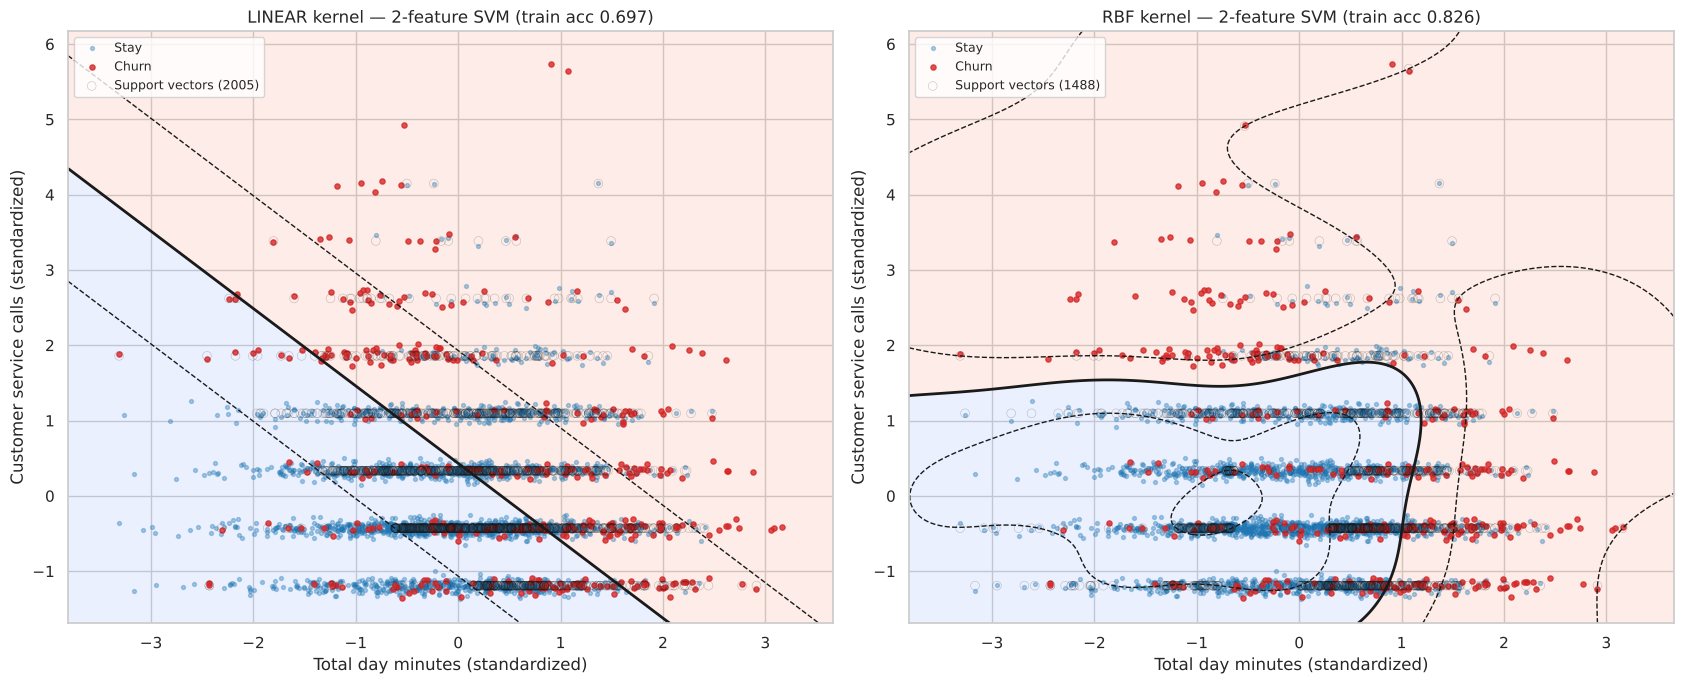

In [7]:
feat2 = ["Total day minutes", "Customer service calls"]
sc2 = StandardScaler().fit(X_train[feat2])
X2 = sc2.transform(X_train[feat2])
rng = np.random.default_rng(RANDOM_STATE)
X2_plot = X2 + np.c_[np.zeros(len(X2)), rng.normal(0, .06, len(X2))]   # small jitter: service calls are integers

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 400),
                     np.linspace(X2[:, 1].min() - .5, X2[:, 1].max() + .5, 400))
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (kname, params) in zip(axes, [("linear", {"C": 1}), ("rbf", {"C": 1, "gamma": 0.3})]):
    clf = SVC(kernel=kname, class_weight="balanced", **params).fit(X2, y_train)
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=.18, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(X2_plot[y_train == 0, 0], X2_plot[y_train == 0, 1], s=8, c="tab:blue", alpha=.35, label="Stay")
    ax.scatter(X2_plot[y_train == 1, 0], X2_plot[y_train == 1, 1], s=14, c="tab:red", alpha=.8, label="Churn")
    ax.scatter(X2[clf.support_, 0], X2[clf.support_, 1], s=40, facecolors="none", edgecolors="k", linewidths=.4,
               alpha=.25, label=f"Support vectors ({len(clf.support_)})")
    acc = clf.score(X2, y_train)
    ax.set_title(f"{kname.upper()} kernel — 2-feature SVM (train acc {acc:.3f})")
    ax.set_xlabel("Total day minutes (standardized)"); ax.set_ylabel("Customer service calls (standardized)")
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig(IMG / "decision_boundary.png", dpi=120); plt.show()

The **linear** boundary can only draw one straight line, so it misses the pattern. The **RBF** boundary bends: it flags
customers with *very high day minutes* **or** *4+ service calls* — and both at once — which is exactly the shape of the
churn data seen in the EDA of earlier tasks.

## Conclusions
| Kernel | CV ROC-AUC | Test accuracy | Precision | Recall | F1 | **Test AUC** |
|---|---|---|---|---|---|---|
| Linear (C = 10) | 0.814 | 0.772 | 0.362 | 0.789 | 0.497 | 0.832 |
| **RBF (C = 1, gamma = "scale")** | **0.891** | **0.879** | **0.554** | 0.758 | **0.640** | **0.918** |
| Polynomial (degree 2) | 0.873 | 0.852 | 0.487 | 0.768 | 0.596 | 0.896 |

* The **RBF kernel is clearly the best** (test AUC 0.918 vs 0.832 for linear). Churn is a non-linear problem — risk jumps
  after a threshold of service calls and day minutes — and the linear kernel can only separate classes with a flat hyperplane
  (its result is almost identical to logistic regression from Level 2, AUC ≈ 0.82).
* Because of `class_weight="balanced"`, all kernels find ~76–79 % of churners; the RBF kernel does it with far fewer false alarms
  (precision 0.55 vs 0.36).
* The decision-boundary plot makes the difference visible: the linear boundary is a single diagonal line, the RBF boundary
  wraps around the "safe" region (normal usage, ≤ 3 service calls).
* Compared with the tuned Random Forest (test F1 0.86, AUC 0.935), the RBF-SVM is slightly weaker on this tabular dataset,
  but it is a strong second choice.